# MNIST: layer-wise SPSA vs. Adam

**Implementation by:** Ananth Shyam, Rama Narasimha and Mahan Bhimireddy.

This notebook compares two ways of training the **same network on MNIST**:

| | **layer-wise SPSA** (Wulff et al., ICANN 2018) | **Adam** (Kingma & Ba, 2015) |
|---|---|---|
| gradient | *estimated* from 2 forward passes per step: $\hat g = \frac{f(w+c\delta)-f(w-c\delta)}{2c}\,\delta$ | *exact*, by backpropagation |
| what is updated per step | one block (a layer's weights *or* its biases) | all parameters |
| updates per epoch | 6 blocks × 50 iterations = 300 | 1 (full batch) |
| settings | paper: a = c = 0.1, t_max = 50, bottom-up, weights then biases; α = 0.602, γ = 0.101 | lr = 3·10⁻⁴, betas 0.9 / 0.999, full batch |

Both use the same tanh network, the same Glorot initialisation scheme and the same squared-residual
loss with one-hot targets. The default network is **784×784×196×10 = 771,270 parameters**, the count
the paper states; set `HIDDEN = [196]` for the paper's prose topology 784×196×10 (155,830 parameters).

The training code is the tested `spsa_nn` package of this repository. The paper-walkthrough notebook
`SPSA_layerwise_training.ipynb` writes the same algorithm out cell by cell.

**Run time** on an RTX 3050 laptop GPU: about 7 minutes (SPSA ≈ 5 min for 3 runs, Adam ≈ 1.5 min).

**Contents**
1. Setup and data
2. Training
3. Loss curves
4. Accuracy curves
5. Accuracy against compute and time
6. Confusion matrices
7. Per-class precision, recall and F1
8. Most-confused digit pairs
9. Predictions on test images
10. Prediction confidence
11. How far each optimizer moves the weights
12. Summary

## 1. Setup and data

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

NB_DIR = Path.cwd()
ROOT = NB_DIR.parent if (NB_DIR.parent / "spsa_nn").exists() else NB_DIR
sys.path.insert(0, str(ROOT))

from spsa_nn import datasets, gd, layerwise, mlp, get_device
from spsa_nn.device import describe, make_generator, seed_everything

# ---- configuration -------------------------------------------------------------
HIDDEN = [784, 196]      # 771,270 parameters (paper's count); [196] -> 784x196x10, 155,830 parameters
SPSA_RUNS = 3            # independent SPSA runs, trained in parallel (paper: 3)
SPSA_EPOCHS = 12         # paper: 12
ADAM_EPOCHS = 250        # same length as the paper's gradient-descent baseline
ADAM_LR = 3e-4           # 1e-3 collapses to a single predicted class on the 771k network
SEED = 0
QUICK = False            # True: 10k training images, 3 SPSA / 20 Adam epochs (smoke test)
# ---------------------------------------------------------------------------------

if QUICK:
    SPSA_EPOCHS, ADAM_EPOCHS = 3, 20
SIZES = [784, *HIDDEN, 10]
BETA = 1.0
OUT = NB_DIR / ("mnist_spsa_vs_adam_results_quick" if QUICK else "mnist_spsa_vs_adam_results")
OUT.mkdir(parents=True, exist_ok=True)

seed_everything(SEED)
DEVICE = get_device("auto")
print(f"device: {describe(DEVICE)} | torch {torch.__version__}")
print(f"network {'x'.join(map(str, SIZES))}: {mlp.count_parameters(SIZES):,d} parameters")
print("results ->", OUT.resolve())

device: cuda:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU) | torch 2.14.0+cu126
network 784x784x196x10: 771,270 parameters
results -> D:\SPSA implementation\spsa-layerwise\notebooks\mnist_spsa_vs_adam_results


train (60000, 784)  test (10000, 784)  pixels in [0, 1]


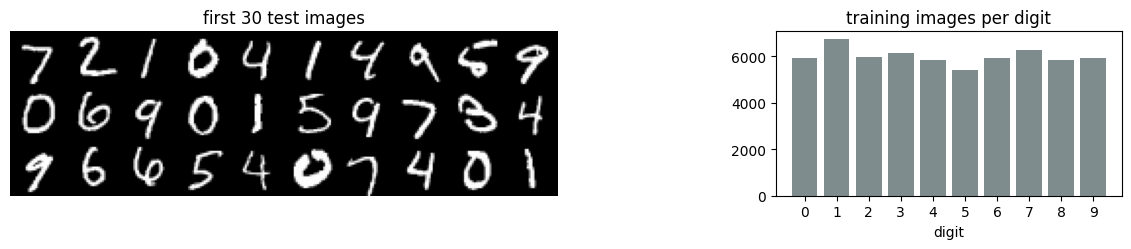

In [2]:
train, test = datasets.load_mnist(n_train=10000 if QUICK else None)      # downloads on first use
xtr, ytr, ltr = train.x.to(DEVICE), train.y.to(DEVICE), train.labels.to(DEVICE)
xte, yte, lte = test.x.to(DEVICE), test.y.to(DEVICE), test.labels.to(DEVICE)
print(f"train {tuple(xtr.shape)}  test {tuple(xte.shape)}  pixels in [{xtr.min().item():.0f}, {xtr.max().item():.0f}]")

counts = torch.bincount(ltr, minlength=10).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 2.6), gridspec_kw={"width_ratios": [3, 1.2]})
grid = test.x[:30].view(3, 10, 28, 28).permute(0, 2, 1, 3).reshape(84, 280)
axes[0].imshow(grid, cmap="gray"); axes[0].axis("off"); axes[0].set_title("first 30 test images")
axes[1].bar(range(10), counts, color="#7f8c8d"); axes[1].set_xticks(range(10))
axes[1].set_title("training images per digit"); axes[1].set_xlabel("digit")
plt.tight_layout(); plt.show()

## 2. Training

Each run records, after every epoch: the training error $E/n$ (Eq. 9 divided by n), the test
error, and the training and test accuracy. Adam is also run separately for exactly `SPSA_EPOCHS`
epochs. That gives its weights at epoch 12, for a like-for-like comparison with SPSA's final weights
(the run is deterministic, so they are the same weights its 250-epoch run has at epoch 12).

In [3]:
def eval_fn(p):
    return {"test_acc": mlp.accuracy(xte, lte, p, BETA),
            "train_acc": mlp.accuracy(xtr, ltr, p, BETA),
            "test_error": mlp.evaluate_error(xte, yte, p, BETA, "mean")}

spsa_cfg = layerwise.TrainConfig(
    sizes=SIZES, order="bottom-up", epochs=SPSA_EPOCHS, beta=BETA, n_trials=SPSA_RUNS,
    reduction="elementwise_mean", report_reduction="mean", split_bias=True, init="glorot", seed=SEED,
    spsa=layerwise.SPSAConfig(a=0.1, c=0.1, alpha=0.602, gamma=0.101, t_max=50))
spsa_params, spsa = layerwise.train(xtr, ytr, spsa_cfg, DEVICE, eval_fn=eval_fn, log_every=1, log_prefix="[SPSA] ")
print("SPSA final test accuracy per run:", [round(v, 4) for v in spsa["test_acc"][-1]])

[SPSA] epoch    1/12  E mean    2.1443  median    2.0692  test_acc 0.2655  train_acc 0.2689  test_error 2.1327  (22.9s)


[SPSA] epoch    2/12  E mean    2.2156  median    2.0505  test_acc 0.3754  train_acc 0.3783  test_error 2.2047  (45.6s)


[SPSA] epoch    3/12  E mean    2.3795  median    2.4408  test_acc 0.4314  train_acc 0.4248  test_error 2.3569  (68.3s)


[SPSA] epoch    4/12  E mean    2.3518  median    2.3612  test_acc 0.4828  train_acc 0.4728  test_error 2.3342  (91.1s)


[SPSA] epoch    5/12  E mean    2.4184  median    2.4670  test_acc 0.4978  train_acc 0.4899  test_error 2.4016  (113.9s)


[SPSA] epoch    6/12  E mean    2.4593  median    2.4936  test_acc 0.4959  train_acc 0.4890  test_error 2.4492  (136.7s)


... (3 outputs left out)

[SPSA] epoch   10/12  E mean    2.7169  median    2.7448  test_acc 0.5075  train_acc 0.5039  test_error 2.7006  (227.9s)


[SPSA] epoch   11/12  E mean    2.7588  median    2.7905  test_acc 0.5144  train_acc 0.5133  test_error 2.7511  (250.6s)


[SPSA] epoch   12/12  E mean    2.7793  median    2.7927  test_acc 0.5149  train_acc 0.5092  test_error 2.7590  (273.4s)


SPSA final test accuracy per run: [0.4811, 0.5584, 0.5053]


In [4]:
adam_cfg = gd.GDConfig(sizes=SIZES, lr=ADAM_LR, epochs=ADAM_EPOCHS, optimizer="adam", beta=BETA,
                       init="glorot", seed=SEED)
adam_params, adam = gd.train(xtr, ytr, adam_cfg, DEVICE, eval_fn=eval_fn,
                             log_every=max(1, ADAM_EPOCHS // 10), log_prefix="[Adam] ")

adam12_cfg = gd.GDConfig(**{**adam_cfg.to_dict(), "epochs": SPSA_EPOCHS})
adam12_params, _ = gd.train(xtr, ytr, adam12_cfg, DEVICE)
acc12 = mlp.accuracy(xte, lte, adam12_params, BETA).item()
print(f"Adam after {SPSA_EPOCHS} epochs: test accuracy {acc12:.4f} "
      f"(250-epoch run at epoch {SPSA_EPOCHS}: {adam['test_acc'][SPSA_EPOCHS][0]:.4f})")

with open(OUT / "histories.json", "w") as f:
    json.dump({"sizes": SIZES, "spsa": {"config": spsa_cfg.to_dict(), **spsa},
               "adam": {"config": adam_cfg.to_dict(), **adam}}, f)

[Adam] epoch   25/250  E 0.5323  test_acc 0.8182  train_acc 0.8092  test_error 0.5237  (4.0s)


[Adam] epoch   50/250  E 0.4223  test_acc 0.8597  train_acc 0.8533  test_error 0.4195  (7.7s)


[Adam] epoch   75/250  E 0.3736  test_acc 0.8807  train_acc 0.8743  test_error 0.3722  (11.4s)


[Adam] epoch  100/250  E 0.3376  test_acc 0.8939  train_acc 0.8898  test_error 0.3370  (15.1s)


[Adam] epoch  125/250  E 0.3077  test_acc 0.9072  train_acc 0.9029  test_error 0.3075  (18.7s)


[Adam] epoch  150/250  E 0.2827  test_acc 0.9158  train_acc 0.9127  test_error 0.2828  (22.4s)


[Adam] epoch  175/250  E 0.2617  test_acc 0.9215  train_acc 0.9203  test_error 0.2621  (26.1s)


[Adam] epoch  200/250  E 0.2441  test_acc 0.9277  train_acc 0.9266  test_error 0.2447  (29.9s)


[Adam] epoch  225/250  E 0.2291  test_acc 0.9321  train_acc 0.9319  test_error 0.2300  (33.6s)


[Adam] epoch  250/250  E 0.2164  test_acc 0.9366  train_acc 0.9359  test_error 0.2177  (37.3s)


Adam after 12 epochs: test accuracy 0.7843 (250-epoch run at epoch 12: 0.7843)


In [5]:
A = lambda h, k: np.asarray(h[k], dtype=float)        # (epochs+1, runs)
ep_s, ep_a = np.arange(SPSA_EPOCHS + 1), np.arange(ADAM_EPOCHS + 1)
C_SPSA, C_ADAM = "#3b4cc0", "#1e8c3a"

# Which SPSA run to show in the per-model analyses: the run with the median final test accuracy
final_spsa = A(spsa, "test_acc")[-1]
MED = int(np.argsort(final_spsa)[len(final_spsa) // 2])
spsa_one = [p[MED:MED + 1] for p in spsa_params]
print(f"SPSA runs, final test accuracy: {np.round(final_spsa, 4)} -> median run = run {MED}")

MODELS = {f"SPSA (epoch {SPSA_EPOCHS}, run {MED})": spsa_one,
          f"Adam (epoch {SPSA_EPOCHS})": adam12_params,
          f"Adam (epoch {ADAM_EPOCHS})": adam_params}
MODEL_COLORS = [C_SPSA, "#8fd19e", C_ADAM]

SPSA runs, final test accuracy: [0.4811 0.5584 0.5053] -> median run = run 2


## 3. Loss curves

The training error $E(\mathcal D, \mathcal W_e)/n$ is the objective both optimizers minimise (SPSA
works on the same quantity divided by 10, which only rescales its step size). Thin blue lines are the
individual SPSA runs and the thick line is their mean. The x-axis is linear up to epoch 15 and
logarithmic after, so the first epochs and the long Adam run are both readable.

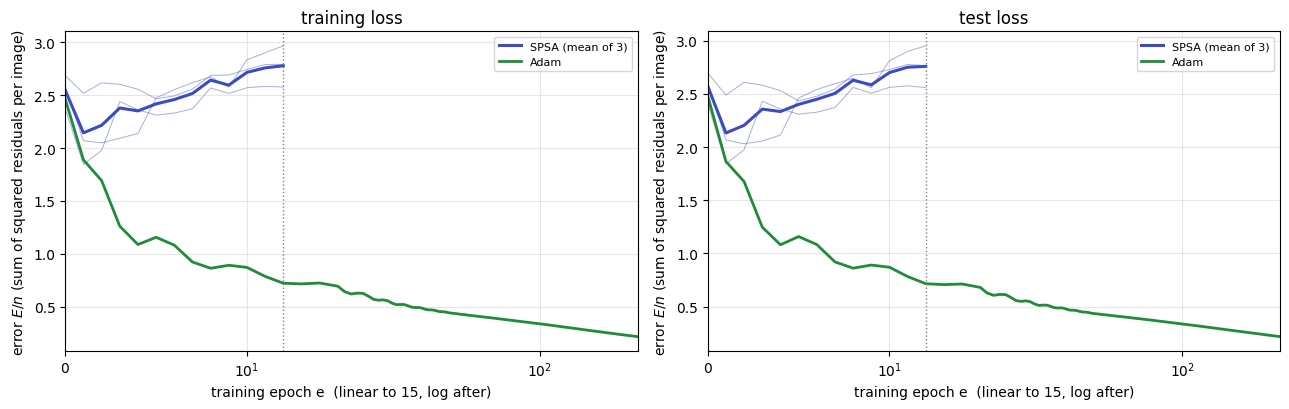

In [6]:
def style(ax, title, ylabel, xmax):
    ax.set_xscale("symlog", linthresh=15); ax.set_xlim(0, xmax)
    ax.set_xlabel("training epoch e  (linear to 15, log after)"); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key, title in ((axes[0], "error", "training loss"), (axes[1], "test_error", "test loss")):
    for r in range(SPSA_RUNS):
        ax.plot(ep_s, A(spsa, key)[:, r], color=C_SPSA, lw=.7, alpha=.45)
    ax.plot(ep_s, A(spsa, key).mean(1), color=C_SPSA, lw=2.2, label=f"SPSA (mean of {SPSA_RUNS})")
    ax.plot(ep_a, A(adam, key)[:, 0], color=C_ADAM, lw=2, label="Adam")
    ax.axvline(SPSA_EPOCHS, color="gray", ls=":", lw=1)
    style(ax, title, r"error $E/n$ (sum of squared residuals per image)", ADAM_EPOCHS)
plt.tight_layout(); plt.savefig(OUT / "loss_curves.png", dpi=150); plt.show()

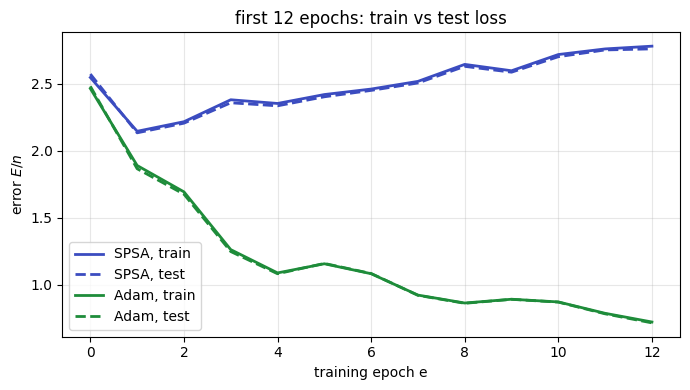

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ep_s, A(spsa, "error").mean(1), color=C_SPSA, lw=2, label="SPSA, train")
ax.plot(ep_s, A(spsa, "test_error").mean(1), color=C_SPSA, lw=2, ls="--", label="SPSA, test")
ax.plot(ep_s, A(adam, "error")[:SPSA_EPOCHS + 1, 0], color=C_ADAM, lw=2, label="Adam, train")
ax.plot(ep_s, A(adam, "test_error")[:SPSA_EPOCHS + 1, 0], color=C_ADAM, lw=2, ls="--", label="Adam, test")
ax.set_xlabel("training epoch e"); ax.set_ylabel(r"error $E/n$"); ax.grid(alpha=.3); ax.legend()
ax.set_title(f"first {SPSA_EPOCHS} epochs: train vs test loss")
plt.tight_layout(); plt.savefig(OUT / "loss_first_epochs.png", dpi=150); plt.show()

## 4. Accuracy curves

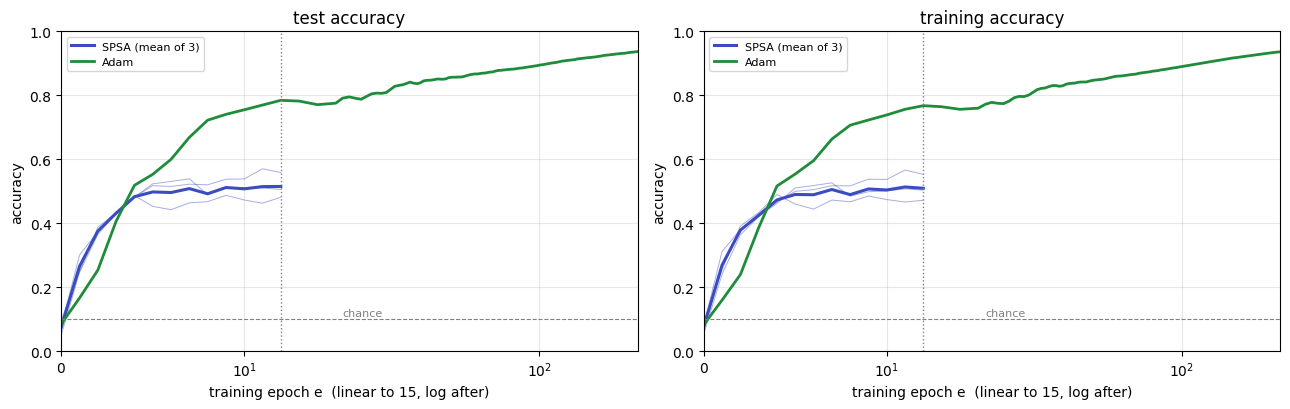

 epoch  SPSA test acc  Adam test acc
     1          0.265          0.166
     2          0.375          0.254
     3          0.431          0.407
     5          0.498          0.553
     8          0.492          0.722
    12          0.515          0.784
    25              -          0.818
    50              -          0.860
   100              -          0.894
   250              -          0.937


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key, title in ((axes[0], "test_acc", "test accuracy"), (axes[1], "train_acc", "training accuracy")):
    for r in range(SPSA_RUNS):
        ax.plot(ep_s, A(spsa, key)[:, r], color=C_SPSA, lw=.7, alpha=.45)
    ax.plot(ep_s, A(spsa, key).mean(1), color=C_SPSA, lw=2.2, label=f"SPSA (mean of {SPSA_RUNS})")
    ax.plot(ep_a, A(adam, key)[:, 0], color=C_ADAM, lw=2, label="Adam")
    ax.axhline(0.1, color="gray", lw=.8, ls="--"); ax.text(16, 0.11, "chance", color="gray", fontsize=8)
    ax.axvline(SPSA_EPOCHS, color="gray", ls=":", lw=1)
    style(ax, title, "accuracy", ADAM_EPOCHS); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(OUT / "accuracy_curves.png", dpi=150); plt.show()

rows = [(e, A(spsa, "test_acc")[min(e, SPSA_EPOCHS)].mean() if e <= SPSA_EPOCHS else np.nan,
         A(adam, "test_acc")[e, 0]) for e in sorted({1, 2, 3, 5, 8, SPSA_EPOCHS, 25, 50, 100, ADAM_EPOCHS}) if e <= ADAM_EPOCHS]
print(f"{'epoch':>6s} {'SPSA test acc':>14s} {'Adam test acc':>14s}")
for e, s, a in rows:
    print(f"{e:6d} {('%.3f' % s) if not np.isnan(s) else '-':>14s} {a:14.3f}")

## 5. Accuracy against compute and time

Epochs are not equal work for the two optimizers.

* **SPSA:** in each epoch, every block makes 50 iterations, and each iteration evaluates the network
  twice (w + cδ and w − cδ). Only the layers from the active block upwards are evaluated, because the
  layers below are fixed and their output is cached once per block.
* **Adam:** one epoch is one forward and one backward pass over the training set. The backward pass
  costs about 2 forward passes, the usual rule of thumb.

The cell below converts both into **forward-pass equivalents**: multiply-adds divided by those of one
full forward pass over the training set. Wall-clock time is shown too. SPSA trains its
`SPSA_RUNS` runs in one batched program, so its time is per epoch for all runs, and the time also
includes the per-epoch evaluation of both methods.

forward-pass equivalents per epoch: SPSA 244.5, Adam 3.0 -> one SPSA epoch costs as much as 82 Adam epochs


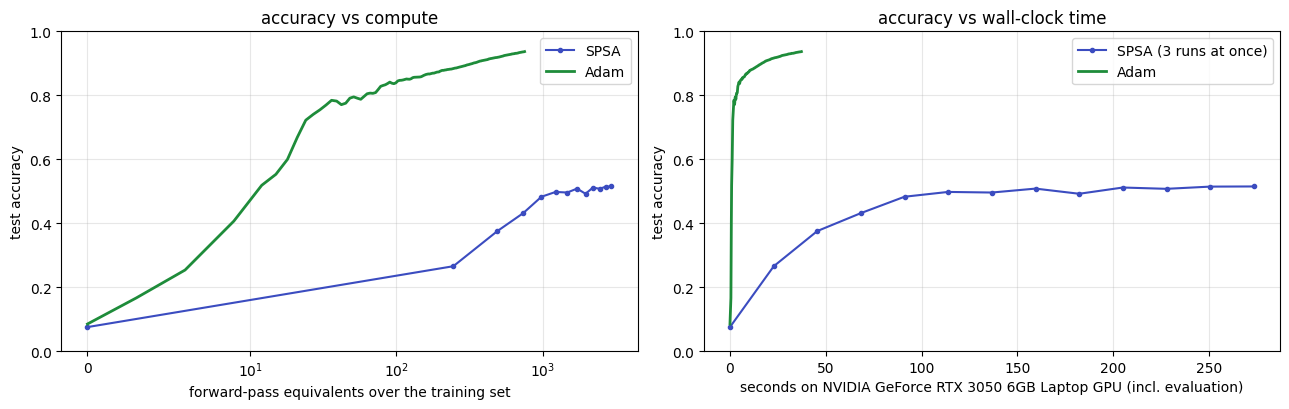

With SPSA's whole 12-epoch budget (2934 forward-pass equivalents), Adam could run 978 epochs; at epoch 250 Adam has test accuracy 0.937 vs SPSA's 0.515.


In [9]:
macs = [a * b for a, b in zip(SIZES[:-1], SIZES[1:])]           # multiply-adds per image, per layer
full = sum(macs)
spsa_epoch_cost = 0.0
for l in range(len(macs)):                                       # bottom-up; weights then biases = 2 blocks per layer
    for _block in range(2):
        spsa_epoch_cost += sum(macs[:l]) / full                  # cache the fixed layers below (once per block)
        spsa_epoch_cost += spsa_cfg.spsa.t_max * 2 * sum(macs[l:]) / full   # 50 iterations x (+ and -)
adam_epoch_cost = 3.0                                            # forward + backward (~2 forward)
print(f"forward-pass equivalents per epoch: SPSA {spsa_epoch_cost:.1f}, Adam {adam_epoch_cost:.1f} "
      f"-> one SPSA epoch costs as much as {spsa_epoch_cost / adam_epoch_cost:.0f} Adam epochs")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(ep_s * spsa_epoch_cost, A(spsa, "test_acc").mean(1), "o-", ms=3, color=C_SPSA, label="SPSA")
ax.plot(ep_a * adam_epoch_cost, A(adam, "test_acc")[:, 0], color=C_ADAM, lw=2, label="Adam")
ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("forward-pass equivalents over the training set")
ax.set_ylabel("test accuracy"); ax.set_title("accuracy vs compute"); ax.grid(alpha=.3, which="both"); ax.legend()
ax = axes[1]
ax.plot(A(spsa, "time")[:, 0] if A(spsa, "time").ndim > 1 else A(spsa, "time"), A(spsa, "test_acc").mean(1),
        "o-", ms=3, color=C_SPSA, label=f"SPSA ({SPSA_RUNS} runs at once)")
ax.plot(A(adam, "time")[:, 0] if A(adam, "time").ndim > 1 else A(adam, "time"), A(adam, "test_acc")[:, 0],
        color=C_ADAM, lw=2, label="Adam")
ax.set_xlabel(f"seconds on {describe(DEVICE).split('(')[-1].rstrip(')')} (incl. evaluation)"); ax.set_ylabel("test accuracy")
ax.set_title("accuracy vs wall-clock time"); ax.grid(alpha=.3); ax.legend()
for a in axes:
    a.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(OUT / "accuracy_vs_compute_time.png", dpi=150); plt.show()

budget = SPSA_EPOCHS * spsa_epoch_cost
k = int(min(ADAM_EPOCHS, budget // adam_epoch_cost))
print(f"With SPSA's whole {SPSA_EPOCHS}-epoch budget ({budget:.0f} forward-pass equivalents), Adam could run "
      f"{budget / adam_epoch_cost:.0f} epochs; at epoch {k} Adam has test accuracy {A(adam, 'test_acc')[k, 0]:.3f} "
      f"vs SPSA's {A(spsa, 'test_acc')[-1].mean():.3f}.")

## 6. Confusion matrices

Rows are the true digit and columns the predicted digit; every row is normalised to 1, so the
diagonal is the recall of each digit. The three models are SPSA after 12 epochs (median run), Adam
after the **same 12 epochs**, and Adam after 250 epochs.

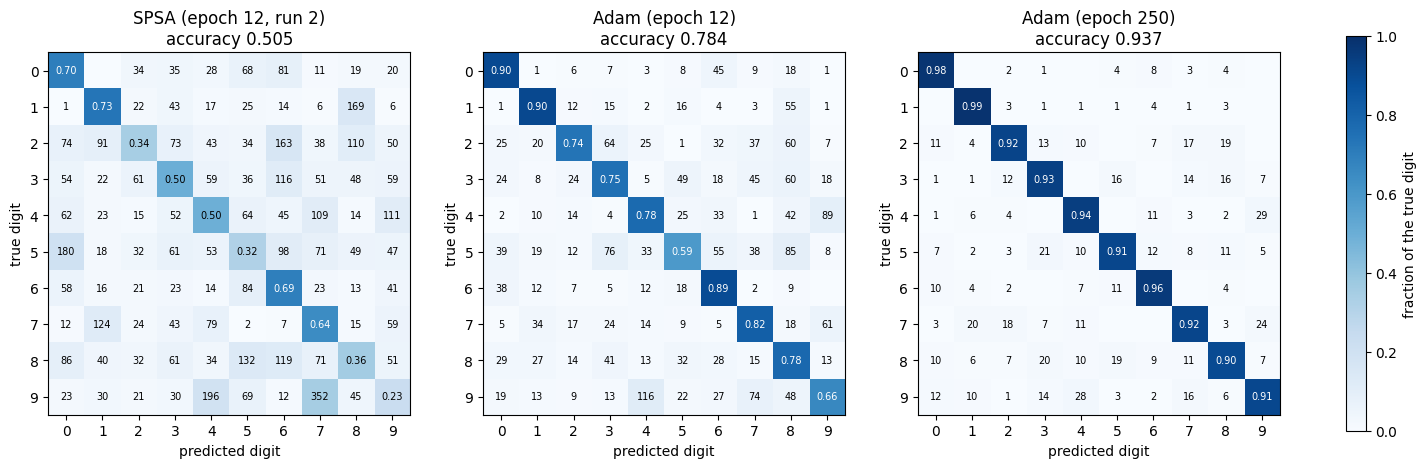

diagonal: recall of that digit; off-diagonal numbers: count of test images


In [10]:
@torch.no_grad()
def confusion(params):
    pred = mlp.predict_classes(xte, params, BETA)[0]
    cm = torch.bincount(lte * 10 + pred, minlength=100).view(10, 10)
    return cm.cpu().numpy(), pred.cpu().numpy()

CMS, PREDS = {}, {}
for name, p in MODELS.items():
    CMS[name], PREDS[name] = confusion(p)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, (name, cm) in zip(axes, CMS.items()):
    norm = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, f"{norm[i, j]:.2f}" if i == j else str(cm[i, j]), ha="center", va="center",
                        fontsize=7, color="white" if norm[i, j] > .5 else "black")
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f"{name}\naccuracy {acc:.3f}"); ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
fig.colorbar(im, ax=axes, fraction=.015, label="fraction of the true digit")
plt.savefig(OUT / "confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()
print("diagonal: recall of that digit; off-diagonal numbers: count of test images")

## 7. Per-class precision, recall and F1

digit | SPSA (epoch 12, run 2) |    Adam (epoch 12)     |    Adam (epoch 250)   
      |   prec    rec     F1  |   prec    rec     F1  |   prec    rec     F1 
    0 |  0.554  0.698  0.618  |  0.829  0.900  0.863  |  0.946  0.978  0.961 
    1 |  0.696  0.733  0.714  |  0.877  0.904  0.890  |  0.955  0.988  0.971 
    2 |  0.576  0.345  0.432  |  0.869  0.737  0.798  |  0.948  0.922  0.935 
    3 |  0.545  0.499  0.521  |  0.753  0.751  0.752  |  0.925  0.934  0.929 
    4 |  0.482  0.496  0.489  |  0.774  0.776  0.775  |  0.923  0.943  0.933 
    5 |  0.355  0.317  0.335  |  0.745  0.591  0.659  |  0.938  0.911  0.924 
    6 |  0.504  0.694  0.584  |  0.776  0.892  0.830  |  0.946  0.960  0.953 
    7 |  0.475  0.645  0.547  |  0.790  0.818  0.804  |  0.928  0.916  0.922 
    8 |  0.419  0.357  0.386  |  0.659  0.782  0.715  |  0.928  0.898  0.913 
    9 |  0.342  0.229  0.274  |  0.771  0.662  0.713  |  0.927  0.909  0.918 
macro |  0.495  0.501  0.490  |  0.784  0.781  0.780  |  0.93

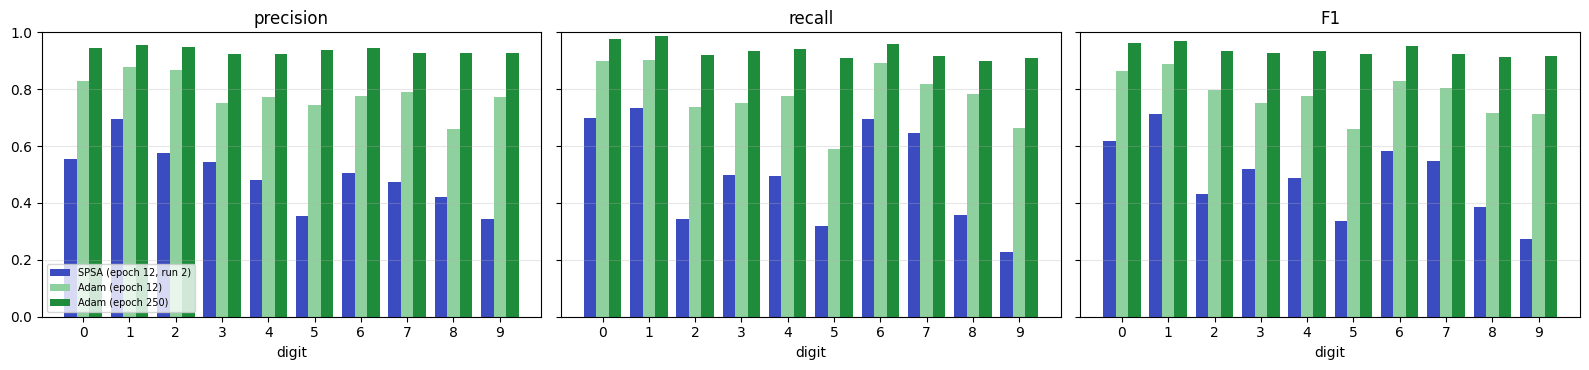

In [11]:
def per_class(cm):
    tp = np.diag(cm).astype(float)
    precision = np.divide(tp, cm.sum(0), out=np.zeros(10), where=cm.sum(0) > 0)
    recall = tp / cm.sum(1)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(10), where=(precision + recall) > 0)
    return precision, recall, f1

METRICS = {name: per_class(cm) for name, cm in CMS.items()}
names = list(METRICS)
print(f"{'digit':>5s} | " + " | ".join(f"{n[:22]:^22s}" for n in names))
print(f"{'':>5s} | " + " | ".join(f"{'prec':>6s} {'rec':>6s} {'F1':>6s} " for _ in names))
for d in range(10):
    print(f"{d:5d} | " + " | ".join(f"{METRICS[n][0][d]:6.3f} {METRICS[n][1][d]:6.3f} {METRICS[n][2][d]:6.3f} " for n in names))
print(f"{'macro':>5s} | " + " | ".join(f"{METRICS[n][0].mean():6.3f} {METRICS[n][1].mean():6.3f} {METRICS[n][2].mean():6.3f} " for n in names))
for n in names:
    never = [d for d in range(10) if CMS[n][:, d].sum() == 0]
    if never:
        print(f"note: {n} never predicts digit(s) {never} (precision set to 0)")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
w = 0.27
for ax, (mi, mname) in zip(axes, enumerate(("precision", "recall", "F1"))):
    for k, (n, c) in enumerate(zip(names, MODEL_COLORS)):
        ax.bar(np.arange(10) + (k - 1) * w, METRICS[n][mi], w, color=c, label=n)
    ax.set_xticks(range(10)); ax.set_xlabel("digit"); ax.set_title(mname); ax.grid(alpha=.3, axis="y")
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "per_class_metrics.png", dpi=150); plt.show()

## 8. Most-confused digit pairs

In [12]:
def top_confusions(cm, k=8):
    off = cm.copy(); np.fill_diagonal(off, 0)
    idx = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1], off.shape))[0][:k]
    return [(int(i), int(j), int(off[i, j])) for i, j in idx]

for name, cm in CMS.items():
    pairs = top_confusions(cm)
    print(f"{name}: " + ", ".join(f"{i}->{j} ({n})" for i, j, n in pairs))

SPSA (epoch 12, run 2): 9->7 (352), 9->4 (196), 5->0 (180), 1->8 (169), 2->6 (163), 8->5 (132), 7->1 (124), 8->6 (119)
Adam (epoch 12): 9->4 (116), 4->9 (89), 5->8 (85), 5->3 (76), 9->7 (74), 2->3 (64), 7->9 (61), 2->8 (60)
Adam (epoch 250): 4->9 (29), 9->4 (28), 7->9 (24), 5->3 (21), 8->3 (20), 7->1 (20), 8->5 (19), 2->8 (19)


## 9. Predictions on test images

The first 24 test images with the predictions of SPSA (epoch 12) and Adam (epoch 250). A red label
is a wrong prediction. The second grid shows images that **Adam gets right but SPSA gets wrong**, and
the third shows the reverse.

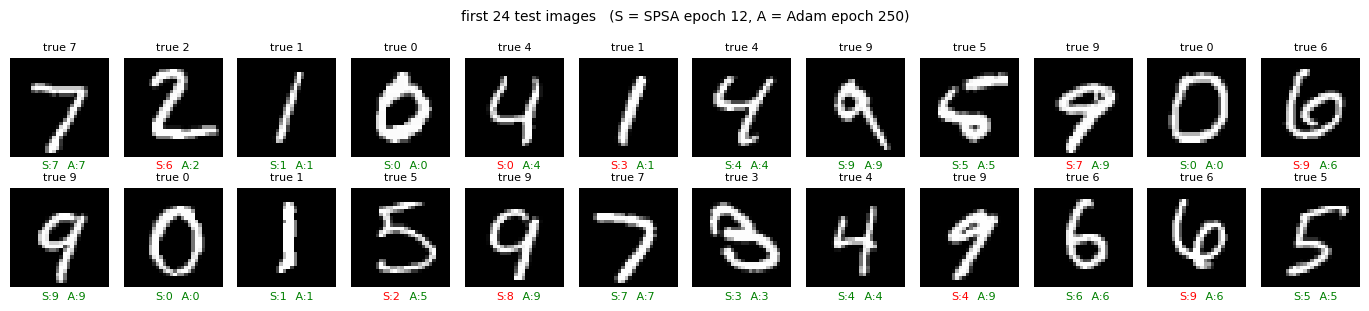

test images: Adam right & SPSA wrong 4402, SPSA right & Adam wrong 89, both wrong 545


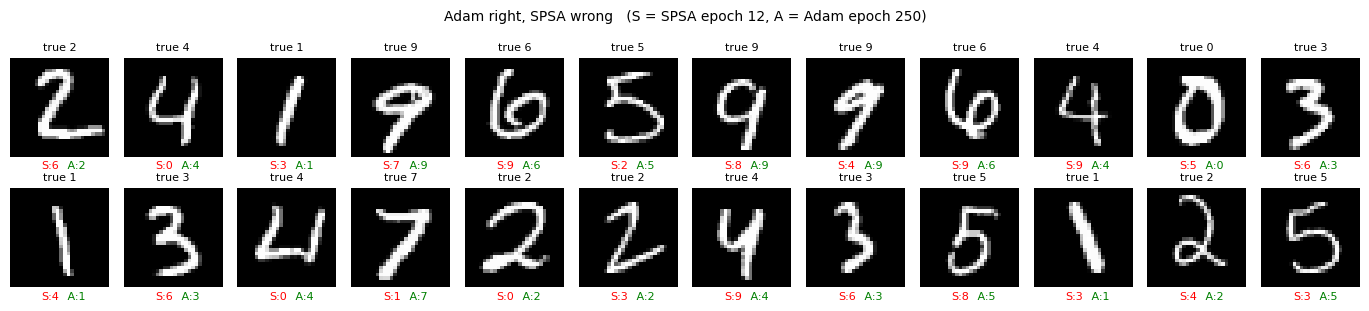

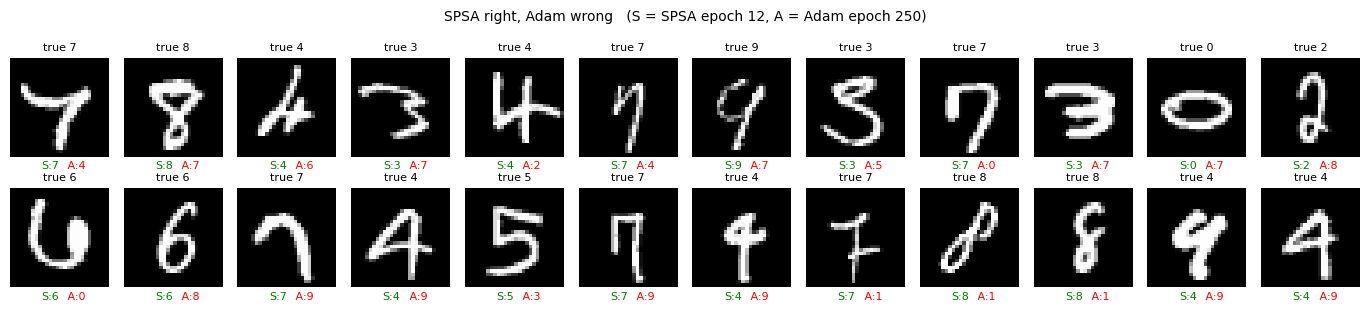

In [13]:
labels_np = lte.cpu().numpy()
imgs = test.x.view(-1, 28, 28).numpy()
s_name, a12_name, a_name = names

def grid_plot(indices, title, path):
    n = len(indices); cols = 12; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.15, rows * 1.55))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).ravel(), indices):
        ax.imshow(imgs[i], cmap="gray")
        ps, pa = PREDS[s_name][i], PREDS[a_name][i]
        ax.set_title(f"true {labels_np[i]}", fontsize=8)
        ax.text(0.5, -0.12, f"S:{ps}", color="green" if ps == labels_np[i] else "red", fontsize=8,
                transform=ax.transAxes, ha="right")
        ax.text(0.55, -0.12, f" A:{pa}", color="green" if pa == labels_np[i] else "red", fontsize=8,
                transform=ax.transAxes, ha="left")
    fig.suptitle(title + "   (S = SPSA epoch 12, A = Adam epoch 250)", fontsize=10)
    plt.tight_layout(); plt.savefig(path, dpi=130); plt.show()

grid_plot(range(24), "first 24 test images", OUT / "sample_predictions.png")
adam_only = np.where((PREDS[a_name] == labels_np) & (PREDS[s_name] != labels_np))[0]
spsa_only = np.where((PREDS[s_name] == labels_np) & (PREDS[a_name] != labels_np))[0]
both_wrong = np.where((PREDS[s_name] != labels_np) & (PREDS[a_name] != labels_np))[0]
print(f"test images: Adam right & SPSA wrong {len(adam_only)}, SPSA right & Adam wrong {len(spsa_only)}, "
      f"both wrong {len(both_wrong)}")
if len(adam_only):
    grid_plot(adam_only[:24], "Adam right, SPSA wrong", OUT / "adam_right_spsa_wrong.png")
if len(spsa_only):
    grid_plot(spsa_only[:24], "SPSA right, Adam wrong", OUT / "spsa_right_adam_wrong.png")

## 10. Prediction confidence

The network's output for an image is 10 tanh values in [−1, 1]. As a confidence score we use the
**margin**: the largest output minus the second largest. A well-trained classifier is confident on
images it classifies correctly and unsure on the ones it gets wrong.

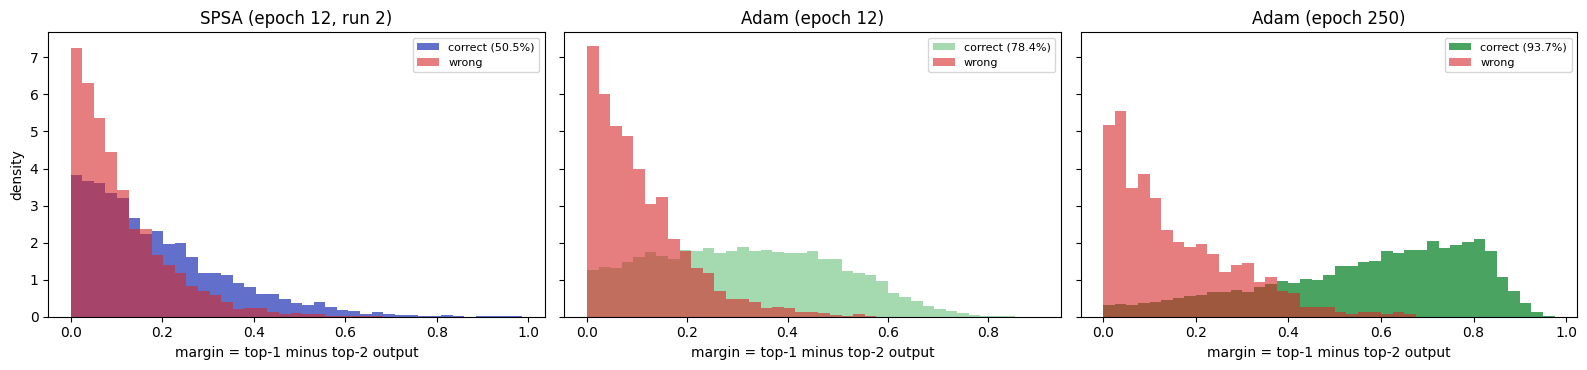

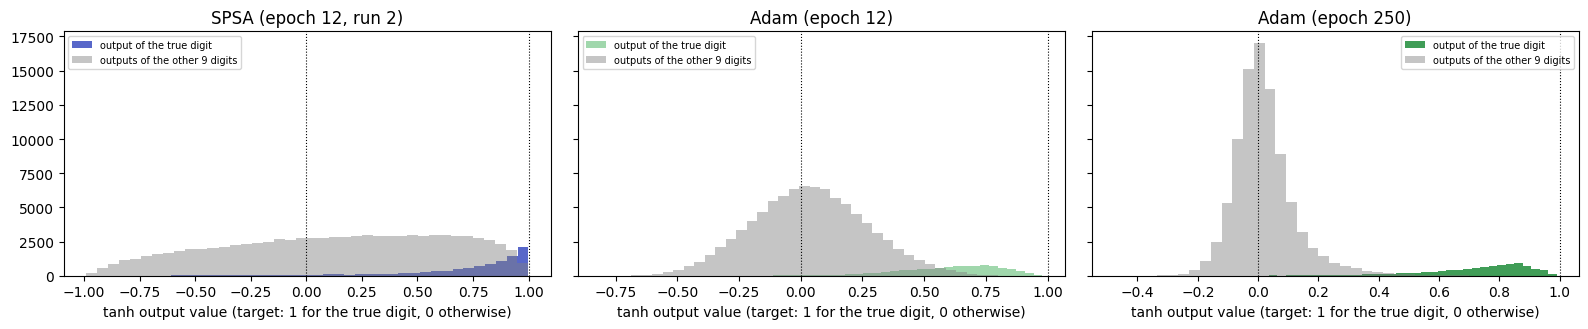

In [14]:
@torch.no_grad()
def margins(params):
    out = mlp.forward(xte, params, BETA)[0]
    top2 = out.topk(2, dim=1).values
    return (top2[:, 0] - top2[:, 1]).cpu().numpy(), out.cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
OUTPUTS = {}
for ax, (name, p), c in zip(axes, MODELS.items(), MODEL_COLORS):
    m, OUTPUTS[name] = margins(p)
    ok = PREDS[name] == labels_np
    bins = np.linspace(0, max(m.max(), 1e-3), 40)
    ax.hist(m[ok], bins, color=c, alpha=.8, label=f"correct ({ok.mean():.1%})", density=True)
    ax.hist(m[~ok], bins, color="#d62728", alpha=.6, label="wrong", density=True)
    ax.set_title(name); ax.set_xlabel("margin = top-1 minus top-2 output"); ax.legend(fontsize=8)
axes[0].set_ylabel("density")
plt.tight_layout(); plt.savefig(OUT / "confidence_margins.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
for ax, (name, out), c in zip(axes, OUTPUTS.items(), MODEL_COLORS):
    ax.hist(out[np.arange(len(out)), labels_np], 40, color=c, alpha=.85, label="output of the true digit")
    mask = np.ones_like(out, dtype=bool); mask[np.arange(len(out)), labels_np] = False
    ax.hist(out[mask], 40, color="gray", alpha=.45, label="outputs of the other 9 digits")
    ax.axvline(1, color="k", ls=":", lw=.8); ax.axvline(0, color="k", ls=":", lw=.8)
    ax.set_title(name); ax.set_xlabel("tanh output value (target: 1 for the true digit, 0 otherwise)")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "output_distributions.png", dpi=150); plt.show()

## 11. How far each optimizer moves the weights

Both runs start from Glorot-initialised weights, regenerated here from the same seeds the trainers
used. The first plot shows, per layer, the relative change $\|W_{final}-W_{init}\| / \|W_{init}\|$.
The second plot shows the change in the input weights of 8 first-layer neurons as 28×28 images.
SPSA moves every weight by the same amount per step along a random ±1 direction, including weights of
pixels that are always black, so its changes are unstructured. Adam only moves weights whose gradient is
non-zero, and it rescales each step to a similar size, so rarely-lit pixels near the border can move as
much as central ones.

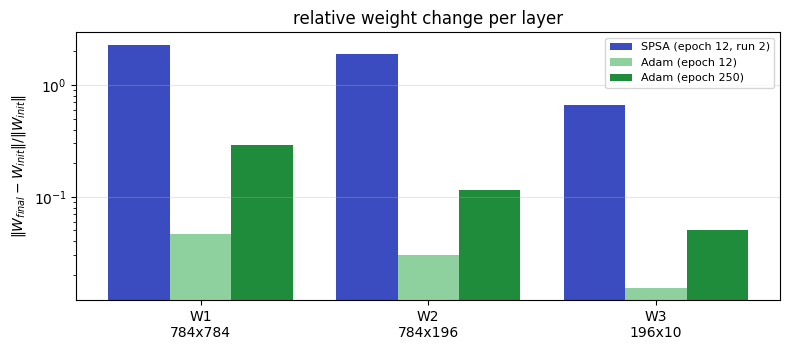

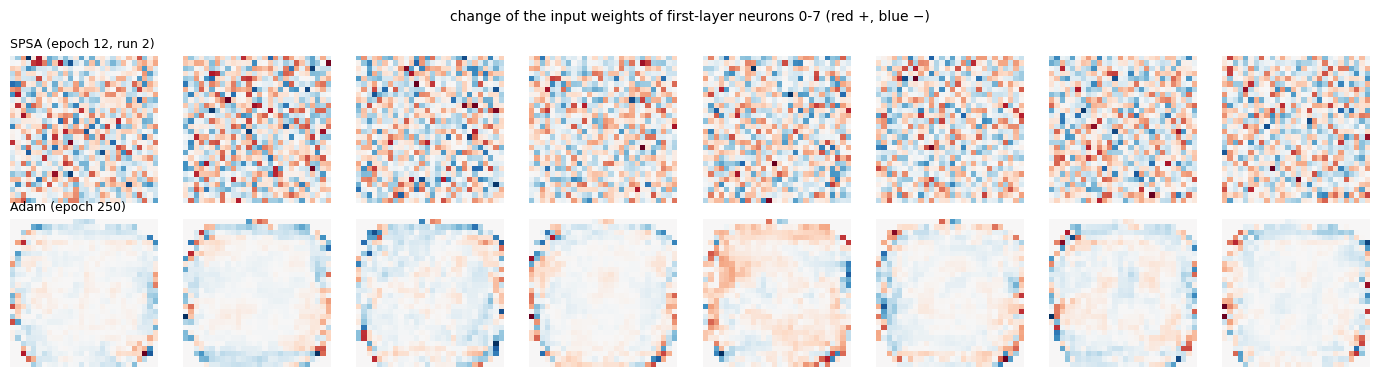

In [15]:
spsa_init = mlp.init_params(SIZES, SPSA_RUNS, "glorot", DEVICE, xtr.dtype, make_generator(SEED, DEVICE))
spsa_init = [p[MED:MED + 1] for p in spsa_init]
adam_init = mlp.init_params(SIZES, 1, "glorot", DEVICE, xtr.dtype, make_generator(SEED, DEVICE))

def rel_change(final, init):
    return [((f - i).norm() / i.norm()).item() for f, i in zip(final[0::2], init[0::2])]

layers = [f"W{l + 1}\n{SIZES[l]}x{SIZES[l + 1]}" for l in range(len(SIZES) - 1)]
rc = {s_name: rel_change(spsa_one, spsa_init), a12_name: rel_change(adam12_params, adam_init),
      a_name: rel_change(adam_params, adam_init)}
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (n, c) in enumerate(zip(rc, MODEL_COLORS)):
    ax.bar(np.arange(len(layers)) + (k - 1) * .27, rc[n], .27, color=c, label=n)
ax.set_xticks(range(len(layers))); ax.set_xticklabels(layers); ax.set_yscale("log")
ax.set_ylabel(r"$\|W_{final}-W_{init}\| / \|W_{init}\|$"); ax.grid(alpha=.3, axis="y"); ax.legend(fontsize=8)
ax.set_title("relative weight change per layer")
plt.tight_layout(); plt.savefig(OUT / "weight_change_per_layer.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for row, (n, fin, ini) in enumerate(((s_name, spsa_one, spsa_init), (a_name, adam_params, adam_init))):
    delta = (fin[0] - ini[0])[0].cpu().numpy()          # (n_hidden1, 784)
    for k, ax in enumerate(axes[row]):
        d = delta[k].reshape(28, 28); v = np.abs(d).max()
        ax.imshow(d, cmap="RdBu_r", vmin=-v, vmax=v); ax.axis("off")
    axes[row, 0].set_title(n, loc="left", fontsize=9)
plt.suptitle("change of the input weights of first-layer neurons 0-7 (red +, blue −)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "first_layer_weight_changes.png", dpi=150); plt.show()

## 12. Summary

In [16]:
def row(name, hist, run=None, epoch=None):
    a = A(hist, "test_acc"); e = A(hist, "error"); te = A(hist, "test_error"); tr = A(hist, "train_acc")
    i = len(a) - 1 if epoch is None else epoch
    pick = (lambda v: v[i].mean()) if run is None else (lambda v: v[i, run])
    return name, i, pick(e), pick(te), pick(tr), pick(a)

summary = [row(f"SPSA, mean of {SPSA_RUNS} runs", spsa), row(f"SPSA, median run {MED}", spsa, run=MED),
           row("Adam", adam, run=0, epoch=SPSA_EPOCHS), row("Adam", adam, run=0)]
print(f"{'model':28s} {'epoch':>5s} {'train loss':>10s} {'test loss':>9s} {'train acc':>9s} {'test acc':>8s}")
for r in summary:
    print(f"{r[0]:28s} {r[1]:5d} {r[2]:10.3f} {r[3]:9.3f} {r[4]:9.3f} {r[5]:8.3f}")
print()
for n in names:
    p, r, f1 = METRICS[n]
    print(f"{n:28s} macro precision {p.mean():.3f}  recall {r.mean():.3f}  F1 {f1.mean():.3f}")

metrics = {"network": SIZES, "parameters": mlp.count_parameters(SIZES), "device": describe(DEVICE),
           "spsa_epoch_cost_forward_equivalents": spsa_epoch_cost, "adam_epoch_cost_forward_equivalents": adam_epoch_cost,
           "summary": [dict(zip(["model", "epoch", "train_loss", "test_loss", "train_acc", "test_acc"], r)) for r in summary],
           "per_class": {n: {"precision": METRICS[n][0].tolist(), "recall": METRICS[n][1].tolist(),
                             "f1": METRICS[n][2].tolist(), "confusion": CMS[n].tolist()} for n in names}}
with open(OUT / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=1)
print("\nsaved figures and metrics to", OUT.resolve())

model                        epoch train loss test loss train acc test acc
SPSA, mean of 3 runs            12      2.779     2.759     0.509    0.515
SPSA, median run 2              12      2.578     2.560     0.503    0.505
Adam                            12      0.721     0.715     0.768    0.784
Adam                           250      0.216     0.218     0.936    0.937

SPSA (epoch 12, run 2)       macro precision 0.495  recall 0.501  F1 0.490
Adam (epoch 12)              macro precision 0.784  recall 0.781  F1 0.780
Adam (epoch 250)             macro precision 0.936  recall 0.936  F1 0.936

saved figures and metrics to D:\SPSA implementation\spsa-layerwise\notebooks\mnist_spsa_vs_adam_results


### What the comparison shows

*(The numbers below are from the saved run on an RTX 3050 with the default 771k network; the printed
output above is from your run.)*

* **SPSA learns without any gradient, and leads for the first 3 epochs.** It reaches 0.43 test
  accuracy after 3 epochs (Adam: 0.41) and 0.515 after 12 (mean of 3 runs, 0.48–0.56), using forward
  passes only.
* **Adam is far better overall.** It overtakes SPSA at epoch 4 (0.518 vs 0.483), reaches 0.784 after the same 12 epochs
  and 0.937 after 250. Its loss falls steadily on train and test. SPSA's falls only in the first epoch,
  then creeps up (2.14 → 2.78) while its accuracy still improves slowly.
* **Per unit of compute, Adam wins from the start.** One SPSA epoch costs about 245 forward-pass
  equivalents, the work of about 80 Adam epochs (Section 5). With the compute SPSA spends on 12 epochs,
  Adam could train for about 980 epochs.
* **The confusion matrices show where SPSA fails.** SPSA's diagonal ranges from 0.73 (digit 1) down to
  0.23 (digit 9). Most of its 9s are predicted as 7 (352) or 4 (196). Adam has the same main
  confusions (9↔4, 9→7, 5→3/8), but far fewer, and after 250 epochs every digit is recognised at ≥ 0.89 (lowest: digit 8, 0.898).
  Macro F1: SPSA 0.49, Adam 0.78 at epoch 12 and 0.94 at epoch 250.
* **SPSA is rarely confident.** Its margin distributions for correct and wrong predictions overlap
  almost completely. Adam separates them clearly: confident when right, unsure when wrong.
* **SPSA moves the weights much further, in random directions.** Relative to the initial weights,
  SPSA changes the 615k-parameter first layer by about 2.3×, and Adam (epoch 250) by about 0.3×.
  SPSA's changes are unstructured noise over every pixel, even pixels that are always black. This is
  the curse of dimensionality the paper describes: with a ±1 perturbation of every weight, most of each
  step is noise.
* **Fairness notes.** SPSA uses the paper's gains; Adam uses lr = 3·10⁻⁴ (its usual 10⁻³ collapses to
  a single class on this network). Both are full batch, with the same loss and initialisation scheme.
  Adam is one run; SPSA is 3 runs.